### SET UP

In [1]:
from datetime import datetime
from pathlib import Path
import importlib
import json
import os
import sys

import pandas as pd
import torch

# Resolve the repository root whether Jupyter starts in the repo or controllers/.
_cwd = Path.cwd().resolve()
REPO_ROOT = next(
    (candidate for candidate in (_cwd, *_cwd.parents)
     if (candidate / "controllers").is_dir() and (candidate / "experiments").is_dir()),
    None,
)
if REPO_ROOT is None:
    raise RuntimeError(f"Could not locate repository root from {_cwd}")
sys.path.insert(0, str(REPO_ROOT))

import core.module05v2_fusion_classifier.dataset as dataset_module
importlib.reload(dataset_module)
import core.module05v2_fusion_classifier.evaluator_profiler as evalprof_module
importlib.reload(evalprof_module)
import core.module05v2_fusion_classifier.pipeline as pipeline_module
importlib.reload(pipeline_module)
from core.module05v2_fusion_classifier.pipeline import FusionBatchPipeline
import core.module03_geometry_extraction.geometry_v2 as geometry_v2_module

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
GLOBAL_RESULTS_SORT_BY = "MCC"  # Options: MCC, AUROC, AUPRC, Accuracy, Precision, Recall, Specificity, F1_Score.
print(f"[*] Device: {DEVICE}")

BASE_DIR = "D:/variant_data"
FM_PROFILE_JSON = f"{BASE_DIR}/profiling/fm_profiling_sequence_ablation.json"
FM_SUPPORT_JSON = f"{BASE_DIR}/profiling/fm_sequence_ablation_support.json"
EMBEDDING_DIR = f"{BASE_DIR}/fm_embeddings/sequence_ablation"
# Geometry k=64 is stored separately from the existing k=32 artifacts.
GEOMETRY_K = 64
GEOMETRY_ROOT_NAME = f"geometry_v2_k{GEOMETRY_K}"
GEOMETRY_DIR = f"{BASE_DIR}/{GEOMETRY_ROOT_NAME}/{{context}}"
GEOM_PROFILE_JSON = None  # No matching k=64 geometry profile is available yet.
GEOM_FEATURE_NAMES = [
    f"{modality}_{feature}"
    for modality in ("dna", "prot")
    for feature in ("LVD_L2", "LVD_Cosine", "LID", "LVD_Relative")
]

# Scope is deliberately limited to the two requested configurations.
TARGET_CONFIGS = [
    {
        "name": "A_no_geometry",
        "ablation": "bio_core_dna_prot_spliceai",
        "active_modalities": ["dna", "prot", "bio_core", "spliceai"],
        "geom_feature_names": None,
    },
    {
        "name": "B_with_geometry",
        "ablation": "bio_core_dna_prot_spliceai_geom",
        "active_modalities": ["dna", "prot", "bio_core", "spliceai", "geom"],
        "geom_feature_names": GEOM_FEATURE_NAMES,
    },
]
DNA_MODEL = {
    "name": "nt_v1_500m_dna_1001",
    "seq_type": "dna",
    "sequence_length": 1001,
}
PROTEIN_MODEL = {
    "name": "esm2_650m_prot_501",
    "seq_type": "protein",
    "sequence_length": 501,
}
MODELS_SPACE = [DNA_MODEL, PROTEIN_MODEL]
SEQUENCE_PAIRS = [(DNA_MODEL["name"], PROTEIN_MODEL["name"])]
pooling_strategies = ["center"]

datasets = [
    {"name": "Train3Val_Test", "train": "train3", "val": "val", "test": "test"},
    {"name": "Train3Val_ClinVarHQ", "train": "train3", "val": "val", "test": "clinvarhq"},
    {"name": "Train3Val_UniProt", "train": "train3", "val": "val", "test": "uniprot"},
    {"name": "Train3Val_ProteinGym", "train": "train3", "val": "val", "test": "proteingym"},
]

# Retain the existing architecture names for baseline lookup and later comparisons.
EXPERIMENTS = [
    {"name": "PyTorch_Concat", "type": "pytorch", "fusion": "concat"},
    {"name": "PyTorch_CrossAttn", "type": "pytorch", "fusion": "cross_attention"},
    {"name": "PyTorch_Transformer", "type": "pytorch", "fusion": "transformer"},
    {"name": "PyTorch_Gating", "type": "pytorch", "fusion": "gating"},
    {"name": "Pure_XGBoost_Concat", "type": "xgboost_pure", "fusion": "concat"},
    {"name": "Hybrid_Concat_XGBoost", "type": "hybrid", "fusion": "concat"},
    {"name": "Hybrid_CrossAttn_XGBoost", "type": "hybrid", "fusion": "cross_attention"},
    {"name": "Hybrid_Transformer_XGBoost", "type": "hybrid", "fusion": "transformer"},
    {"name": "Hybrid_Gating_XGBoost", "type": "hybrid", "fusion": "gating"},
]

CONFIG = {
    "batch_size": 256,
    "epochs": 30,
    "lr": 1e-4,
    "weight_decay": 1e-3,
    "lr_factor": 0.5,
    "lr_patience": 3,
    "early_stop_patience": 6,
    "num_workers": 0,
    "seed": 42,
    "xgb_n_jobs": 1,
}
EXPLAINABILITY = {
    "enable_shap": False,
    "enable_lime": False,
    "max_background_samples": 512,
    "max_explain_samples": 200,
    "lime_num_features": 20,
    "max_lime_samples": 20,
    "random_state": 42,
}

BASELINE_BATCH_RUN_DIR = REPO_ROOT / "experiments" / "batch_run_20261002_2044"

# By default, every notebook run gets a new output directory.
# Set RESUME_EXISTING_RUN=True and provide RESUME_BATCH_RUN_DIR to continue a specific run.
RESUME_EXISTING_RUN = False  # New code/configuration starts in a fresh batch folder.
RESUME_BATCH_RUN_DIR = None  # Set a batch path only when resuming an interrupted run.
if RESUME_EXISTING_RUN:
    if RESUME_BATCH_RUN_DIR is None:
        raise ValueError("Set RESUME_BATCH_RUN_DIR when RESUME_EXISTING_RUN=True")
    RUN_OUTPUT_DIR = Path(RESUME_BATCH_RUN_DIR).resolve()
else:
    _run_stamp = datetime.now().strftime("%Y%m%d_%H%M%S")
    RUN_OUTPUT_DIR = REPO_ROOT / "experiments" / f"optimization_fixed_config_{_run_stamp}"
    _run_suffix = 2
    while RUN_OUTPUT_DIR.exists():
        RUN_OUTPUT_DIR = REPO_ROOT / "experiments" / f"optimization_fixed_config_{_run_stamp}_{_run_suffix:02d}"
        _run_suffix += 1

pipeline = FusionBatchPipeline(
    base_dir=BASE_DIR,
    config=CONFIG,
    datasets=datasets,
    models_space=MODELS_SPACE,
    pooling_strategies=pooling_strategies,
    experiments=EXPERIMENTS,
    explainability=EXPLAINABILITY,
    fm_profile_json=FM_PROFILE_JSON,
    geom_profile_json=GEOM_PROFILE_JSON,
    geometry_dir=GEOMETRY_DIR,
    geom_feature_names=GEOM_FEATURE_NAMES,
    batch_run_dir=str(RUN_OUTPUT_DIR),
    embedding_dir=EMBEDDING_DIR,
)

print(f"[*] Target configs: {[cfg['name'] for cfg in TARGET_CONFIGS]}")
print(f"[*] Fixed models: {DNA_MODEL['name']} + {PROTEIN_MODEL['name']}")
print(f"[*] Pooling: {pooling_strategies}")
print(f"[*] Baseline source: {BASELINE_BATCH_RUN_DIR}")
print(f"[*] New run output: {pipeline.batch_run_dir}")

import core.module05v2_fusion_classifier.ml_experiment_runner as ml_experiment_runner_module
importlib.reload(ml_experiment_runner_module)
ML_SEARCH_CONFIG = ml_experiment_runner_module.get_default_ml_search_config()  # Edit ranges/trial budgets here before starting ML.
ML_CONTEXT = {
    "pipeline": pipeline, "TARGET_CONFIGS": TARGET_CONFIGS, "datasets": datasets,
    "DNA_MODEL": DNA_MODEL, "PROTEIN_MODEL": PROTEIN_MODEL,
    "CONFIG": CONFIG, "DEVICE": DEVICE,
    "GLOBAL_RESULTS_SORT_BY": GLOBAL_RESULTS_SORT_BY,
}



c:\Users\Dung\anaconda3\envs\missense_variant_patho_predict_clean\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


[*] Device: cuda
[*] Target configs: ['A_no_geometry', 'B_with_geometry']
[*] Fixed models: nt_v1_500m_dna_1001 + esm2_650m_prot_501
[*] Pooling: ['center']
[*] Baseline source: D:\Missense_variant_pathogenicity_prediction\experiments\batch_run_20261002_2044
[*] New run output: D:\Missense_variant_pathogenicity_prediction\experiments\optimization_fixed_config_20261026_201426


### Geometry-v2 k=64 preparation and fixed-configuration baseline\n

In [2]:
# Stage 1 ? run the fixed baseline matrix for configurations A and B.
# Each train/validation model is fitted once and reused for the four test datasets.
required_splits = sorted({
    cfg[key]
    for cfg in datasets
    for key in ("train", "val", "test")
})
required_models = [DNA_MODEL["name"], PROTEIN_MODEL["name"]]
missing_embeddings = []
for split in required_splits:
    for model_name in required_models:
        path = Path(EMBEDDING_DIR) / split / f"{model_name}_center.pt"
        if not path.exists():
            missing_embeddings.append(str(path))
if missing_embeddings:
    raise FileNotFoundError(
        f"Missing {len(missing_embeddings)} fixed-config embedding files:\n"
        + "\n".join(missing_embeddings[:20])
    )

for split in required_splits:
    pipeline_module._resolve_bio_path(f"{BASE_DIR}/processed_parquet", split)

if not Path(FM_PROFILE_JSON).exists():
    raise FileNotFoundError(f"Foundation-model profiling file not found: {FM_PROFILE_JSON}")
with open(FM_PROFILE_JSON, "r", encoding="utf-8") as handle:
    fm_profile = json.load(handle)
missing_profile = []
for model_name in required_models:
    for split in sorted({cfg["test"] for cfg in datasets}):
        stats = fm_profile.get(model_name, {}).get(split, {})
        if float(stats.get("inference_time_ms", 0.0) or 0.0) <= 0:
            missing_profile.append(f"{model_name}:{split}")
if missing_profile:
    raise ValueError(f"Missing foundation-model profiling entries: {missing_profile}")

# Configuration B needs geometry generated from these exact sequence-ablation embeddings.
# The default Module 3 input is {BASE_DIR}/fm_embeddings, so pass EMBEDDING_DIR explicitly.
geometry_context_root = Path(GEOMETRY_DIR.format(context="train3"))
geometry_root = str(geometry_context_root)
geometry_output_root = geometry_context_root.parent
expected_geometry = [
    geometry_context_root / split / f"{model_name}_center_geom_v2_norm.parquet"
    for split in required_splits
    for model_name in required_models
]
missing_geometry = [path for path in expected_geometry if not path.exists()]
if missing_geometry:
    print(
        f"[GEOMETRY] Extracting {len(missing_geometry)} missing files from "
        f"the fixed sequence-ablation embeddings."
    )
    try:
        import core.module03_geometry_extraction.geometry_v2 as geometry_v2_module
        importlib.reload(geometry_v2_module)
    except Exception as exc:
        raise RuntimeError(
            "Geometry files are missing and Module 3 could not be imported. "
            "Check that FAISS can load in this Python environment, then rerun this cell."
        ) from exc

    geometry_v2_module.run_geometry_v2(
        geometry_v2_module.GeometryV2Config(
            base_dir=BASE_DIR,
            embedding_dir=EMBEDDING_DIR,
            contexts=["train3"],
            splits=required_splits,
            models=required_models,
            poolings=["center"],
            resume=True,
            geometry_root=geometry_output_root.name,
            k_neighbors=GEOMETRY_K,
            normalization_root=f"normalization_artifacts_v2_k{GEOMETRY_K}",
        )
    )
missing_geometry = [path for path in expected_geometry if not path.exists()]
if missing_geometry:
    raise FileNotFoundError(
        "Geometry-v2 extraction did not produce all required files:\n"
        + "\n".join(str(path) for path in missing_geometry)
    )
for split in required_splits:
    for model_name in required_models:
        pipeline_module._resolve_geom_path(
            geometry_root, split, model_name, "center"
        )
print(f"[GEOMETRY] Ready: {len(expected_geometry)} normalized files.")

# Keep the old wide run as a read-only historical reference, not as the new baseline.
historical_metrics_path = BASELINE_BATCH_RUN_DIR / "global_leaderboard_metrics.csv"
if historical_metrics_path.exists():
    historical_all = pd.read_csv(historical_metrics_path)
    historical_fixed = historical_all.loc[
        historical_all["Pooling"].astype(str).eq("center")
        & historical_all["DNA_Model"].astype(str).eq(DNA_MODEL["name"])
        & historical_all["Prot_Model"].astype(str).eq(PROTEIN_MODEL["name"])
        & historical_all["Ablation"].astype(str).isin(
            [cfg["ablation"] for cfg in TARGET_CONFIGS]
        )
    ].copy()
    historical_path = Path(pipeline.batch_run_dir) / "historical_fixed_config_reference.csv"
    historical_fixed.to_csv(historical_path, index=False)
    print(
        f"[HISTORICAL] Matching rows in batch_run_20261002_2044: "
        f"{len(historical_fixed)}; saved to {historical_path}"
    )
else:
    print(f"[HISTORICAL] No old metrics file found at {historical_metrics_path}")

# Hybrid runs in a dedicated resumable stage below. This cell handles pure baselines.
PURE_BASELINE_EXPERIMENTS = [experiment for experiment in EXPERIMENTS if experiment["type"] != "hybrid"]
from core.module05v2_fusion_classifier.resume_utils import ensure_stage_signature
BASELINE_POLICY_DIR = Path(pipeline.batch_run_dir) / 'fixed_config_baseline_stage'
if not (BASELINE_POLICY_DIR / '_resume_manifest.json').exists() and Path(pipeline.metrics_csv_path).exists():
    _legacy_metrics = pipeline._read_csv_or_empty(pipeline.metrics_csv_path)
    if not _legacy_metrics.empty and 'Network' in _legacy_metrics and _legacy_metrics['Network'].astype(str).str.startswith('PyTorch_').any():
        raise ValueError('This batch contains legacy DL baseline checkpoints selected at threshold 0.5. Start a new batch to apply optimized-threshold checkpoint selection consistently.')
ensure_stage_signature(BASELINE_POLICY_DIR, 'fixed_config_baseline_v2', {
    'experiments': PURE_BASELINE_EXPERIMENTS, 'targets': TARGET_CONFIGS, 'datasets': datasets,
    'config': CONFIG, 'checkpoint_selection': 'validation_mcc_optimized_threshold_v2',
})

# A: no geometry. Run each pure baseline architecture once for this exact model pair.
for experiment in PURE_BASELINE_EXPERIMENTS:
    print(f"\n[BASELINE A] {experiment['name']}")
    pipeline.run_sequence_ablation(
        sequence_pairs=SEQUENCE_PAIRS,
        resume=True,
        experiment_name=experiment["name"],
        pooling="center",
        active_mods=TARGET_CONFIGS[0]["active_modalities"],
    )

# B: same models and architectures, with geometry-v2 enabled.
print("\n[BASELINE B] Full geometry-v2 feature set")
pipeline.run_fixed_geometry_ablation(
    geometry_configs=[{
        "label": TARGET_CONFIGS[1]["ablation"],
        "features": list(TARGET_CONFIGS[1]["geom_feature_names"]),
    }],
    dna_model_name=DNA_MODEL["name"],
    prot_model_name=PROTEIN_MODEL["name"],
    pooling="center",
    experiment_names=[experiment["name"] for experiment in PURE_BASELINE_EXPERIMENTS],
    resume=True,
    run_explainability=False,
)

# Save and display only the results belonging to configurations A and B.
all_baseline_metrics = pd.read_csv(pipeline.metrics_csv_path)
fixed_baseline = all_baseline_metrics.loc[
    all_baseline_metrics["Pooling"].astype(str).eq("center")
    & all_baseline_metrics["DNA_Model"].astype(str).eq(DNA_MODEL["name"])
    & all_baseline_metrics["Prot_Model"].astype(str).eq(PROTEIN_MODEL["name"])
    & all_baseline_metrics["Ablation"].astype(str).isin(
        [cfg["ablation"] for cfg in TARGET_CONFIGS]
    )
].copy()
baseline_path = Path(pipeline.batch_run_dir) / "fixed_config_baseline.csv"
fixed_baseline.to_csv(baseline_path, index=False)

print(f"\n[BASELINE COMPLETE] Output directory: {pipeline.batch_run_dir}")
print(f"[BASELINE COMPLETE] Fixed-config rows: {len(fixed_baseline)}")
print(f"[BASELINE COMPLETE] Filtered CSV: {baseline_path}")
for cfg in TARGET_CONFIGS:
    rows = fixed_baseline.loc[
        fixed_baseline["Ablation"].astype(str).eq(cfg["ablation"])
    ]
    print(f"[BASELINE] {cfg['name']}: {len(rows)} rows")

display(
    fixed_baseline.sort_values(["Ablation", "Dataset", "Network"])
    [["Dataset", "Ablation", "Network", "Decision_Threshold", "MCC", "Val_MCC", "AUROC", "AUPRC"]]
)


[GEOMETRY] Ready: 12 normalized files.
[HISTORICAL] No old metrics file found at D:\Missense_variant_pathogenicity_prediction\experiments\batch_run_20261002_2044\global_leaderboard_metrics.csv

[BASELINE A] PyTorch_Concat

[SEQUENCE ABLATION] DNA=nt_v1_500m_dna_1001 | PROT=esm2_650m_prot_501
[*] Đang nạp dữ liệu bảng (Backbone). Active Mods: ['dna', 'prot', 'bio_core', 'spliceai']
  -> Đang nạp và tiền xử lý DNA Embeddings...
  -> Đang nạp và tiền xử lý Protein Embeddings...
[+] Dataset sẵn sàng: 23208 mẫu. Đã tối ưu hóa RAM & CPU 100%.

[*] Đang nạp dữ liệu bảng (Backbone). Active Mods: ['dna', 'prot', 'bio_core', 'spliceai']
  -> Đang nạp và tiền xử lý DNA Embeddings...
  -> Đang nạp và tiền xử lý Protein Embeddings...
[+] Dataset sẵn sàng: 13701 mẫu. Đã tối ưu hóa RAM & CPU 100%.

[*] Đang nạp dữ liệu bảng (Backbone). Active Mods: ['dna', 'prot', 'bio_core', 'spliceai']
  -> Đang nạp và tiền xử lý DNA Embeddings...
  -> Đang nạp và tiền xử lý Protein Embeddings...
[+] Dataset sẵn sà

[Epoch 01] train_loss=0.3524 | val_loss=0.1986 | val_mcc=0.7642 (threshold=0.5172) | val_f1=0.8089 | val_auroc=0.9637


[Epoch 02] train_loss=0.2339 | val_loss=0.1997 | val_mcc=0.7871 (threshold=0.6963) | val_f1=0.8270 | val_auroc=0.9688


[Epoch 03] train_loss=0.1946 | val_loss=0.2069 | val_mcc=0.7881 (threshold=0.7586) | val_f1=0.8276 | val_auroc=0.9686


[Epoch 04] train_loss=0.1595 | val_loss=0.1935 | val_mcc=0.7910 (threshold=0.5740) | val_f1=0.8315 | val_auroc=0.9677


...

[Epoch 06] train_loss=0.0842 | val_loss=0.2478 | val_mcc=0.7657 (threshold=0.9065) | val_f1=0.8062 | val_auroc=0.9638


[Epoch 07] train_loss=0.0586 | val_loss=0.2706 | val_mcc=0.7602 (threshold=0.8747) | val_f1=0.8040 | val_auroc=0.9611


[Epoch 08] train_loss=0.0345 | val_loss=0.2894 | val_mcc=0.7618 (threshold=0.9396) | val_f1=0.8042 | val_auroc=0.9621


[Epoch 09] train_loss=0.0256 | val_loss=0.3189 | val_mcc=0.7654 (threshold=0.9418) | val_f1=0.8089 | val_auroc=0.9620
[EarlyStop] epoch=9 | best_val_mcc=0.7920
[Test] train3__val_center_bio_core_dna_prot_spliceai_geom_nt_v1_500m_dna_1001_esm2_650m_prot_501_PyTorch_Gating__geom_dna_LVD_L2+dna_LVD_Cosine+dna_LID+dna_LVD_Relative+prot_LVD_L2+prot_LVD_Cosine+prot_LID+prot_LVD_Relative | test=Train3Val_Test | MCC=0.7894 | F1=0.8450 | AUROC=0.9661 | AUPRC=0.9271
[*] Đang nạp dữ liệu bảng (Backbone). Active Mods: ['dna', 'prot', 'bio_core', 'spliceai', 'geom']
  -> Đang nạp và tiền xử lý DNA Embeddings...
  -> Đang nạp và tiền xử lý Protein Embeddings...
[+] Dataset sẵn sàng: 23208 mẫu. Đã tối ưu hóa RAM & CPU 100%.

[*] Đang nạp dữ liệu bảng (Backbone). Active Mods: ['dna', 'prot', 'bio_core', 'spliceai', 'geom']
  -> Đang nạp và tiền xử lý DNA Embeddings...
  -> Đang nạp và tiền xử lý Protein Embeddings...
[+] Dataset sẵn sàng: 13701 mẫu. Đã tối ưu hóa RAM & CPU 100%.

[*] Đang nạp dữ liệu 

,Dataset,Ablation,Network,Decision_Threshold,MCC,Val_MCC,AUROC,AUPRC
1,Train3Val_ClinVarHQ,bio_core_dna_prot_spliceai,Pure_XGBoost_Concat,0.711002,0.8943,0.8169,0.9889,0.9883
2,Train3Val_ClinVarHQ,bio_core_dna_prot_spliceai,PyTorch_Concat,0.574006,0.8531,0.7910,0.9739,0.9706
6,Train3Val_ClinVarHQ,bio_core_dna_prot_spliceai,PyTorch_CrossAttn,0.577072,0.8348,0.7926,0.9758,0.9740
5,Train3Val_ClinVarHQ,bio_core_dna_prot_spliceai,PyTorch_Gating,0.704353,0.8357,0.7962,0.9753,0.9738
3,Train3Val_ClinVarHQ,bio_core_dna_prot_spliceai,PyTorch_Transformer,0.758059,0.8422,0.7833,0.9750,0.9723
13,Train3Val_ProteinGym,bio_core_dna_prot_spliceai,Pure_XGBoost_Concat,0.711002,0.6296,0.8169,0.9052,0.8893
18,Train3Val_ProteinGym,bio_core_dna_prot_spliceai,PyTorch_Concat,0.574006,0.6206,0.7910,0.8933,0.8738
16,Train3Val_ProteinGym,bio_core_dna_prot_spliceai,PyTorch_CrossAttn,0.577072,0.6266,0.7926,0.8934,0.8769
15,Train3Val_ProteinGym,bio_core_dna_prot_spliceai,PyTorch_Gating,0.704353,0.6282,0.7962,0.8928,0.8756
19,Train3Val_ProteinGym,bio_core_dna_prot_spliceai,PyTorch_Transformer,0.758059,0.6139,0.7833,0.8877,0.8706


### Pure XGBoost without PCA - fixed-config Optuna search


In [3]:
import importlib
import core.module05v2_fusion_classifier.global_results as global_results_module
importlib.reload(global_results_module)
import core.module05v2_fusion_classifier.ml_experiment_runner as ml_experiment_runner_module
importlib.reload(ml_experiment_runner_module)
XGB_NO_PCA_RESULTS = ml_experiment_runner_module.run_xgb_no_pca(ML_CONTEXT, ML_SEARCH_CONFIG, display_fn=display)



[Pure XGBoost, no PCA] A_no_geometry
[*] Đang nạp dữ liệu bảng (Backbone). Active Mods: ['dna', 'prot', 'bio_core', 'spliceai']
  -> Đang nạp và tiền xử lý DNA Embeddings...
  -> Đang nạp và tiền xử lý Protein Embeddings...
[+] Dataset sẵn sàng: 23208 mẫu. Đã tối ưu hóa RAM & CPU 100%.

[*] Đang nạp dữ liệu bảng (Backbone). Active Mods: ['dna', 'prot', 'bio_core', 'spliceai']
  -> Đang nạp và tiền xử lý DNA Embeddings...
  -> Đang nạp và tiền xử lý Protein Embeddings...
[+] Dataset sẵn sàng: 13701 mẫu. Đã tối ưu hóa RAM & CPU 100%.

[Features] train=(23208, 2580) | validation=(13701, 2580) | PCA=off
[*] Đang khởi tạo XGBoost...
[+] Huấn luyện xong! Dừng ở cây thứ 179.


[I 2026-10-23 17:48:07,253] A new study created in RDB with name: xgb_no_pca_A_no_geometry


[*] Đang khởi tạo XGBoost...
[+] Huấn luyện xong! Dừng ở cây thứ 2049.
  [01/150] Val_MCC=0.8084 | Val_AUPRC=0.9075 | {'max_depth': 8, 'min_child_weight': 39.84727409321963, 'learning_rate': 0.05100627805979915, 'colsample_bytree': 0.6789267873576292, 'colsample_bylevel': 0.3248149123539492, 'colsample_bynode': 0.32479561626896214, 'subsample': 0.5290418060840998, 'gamma': 8.661761457749352, 'reg_alpha': 0.002570603566117598, 'reg_lambda': 13.311216080736884, 'scale_pos_weight': 0.1612274361660593, 'max_bin': 512}
[*] Đang khởi tạo XGBoost...
[+] Huấn luyện xong! Dừng ở cây thứ 4999.
  [02/150] Val_MCC=0.8118 | Val_AUPRC=0.9095 | {'max_depth': 16, 'min_child_weight': 1.3293771991636345, 'learning_rate': 0.0004705059281907648, 'colsample_bytree': 0.34672360788274703, 'colsample_bylevel': 0.4433937943676302, 'colsample_bynode': 0.6198051453057902, 'subsample': 0.7159725093210578, 'gamma': 2.9122914019804194, 'reg_alpha': 0.0032112643094417484, 'reg_lambda': 0.262108787826544, 'scale_pos_

[I 2026-10-23 19:39:39,220] A new study created in RDB with name: xgb_no_pca_B_with_geometry


[*] Đang khởi tạo XGBoost...
[+] Huấn luyện xong! Dừng ở cây thứ 2049.
  [01/150] Val_MCC=0.8112 | Val_AUPRC=0.9088 | {'max_depth': 8, 'min_child_weight': 39.84727409321963, 'learning_rate': 0.05100627805979915, 'colsample_bytree': 0.6789267873576292, 'colsample_bylevel': 0.3248149123539492, 'colsample_bynode': 0.32479561626896214, 'subsample': 0.5290418060840998, 'gamma': 8.661761457749352, 'reg_alpha': 0.002570603566117598, 'reg_lambda': 13.311216080736884, 'scale_pos_weight': 0.1612274361660593, 'max_bin': 512}
[*] Đang khởi tạo XGBoost...
[+] Huấn luyện xong! Dừng ở cây thứ 4999.
  [02/150] Val_MCC=0.8143 | Val_AUPRC=0.9109 | {'max_depth': 16, 'min_child_weight': 1.3293771991636345, 'learning_rate': 0.0004705059281907648, 'colsample_bytree': 0.34672360788274703, 'colsample_bylevel': 0.4433937943676302, 'colsample_bynode': 0.6198051453057902, 'subsample': 0.7159725093210578, 'gamma': 2.9122914019804194, 'reg_alpha': 0.0032112643094417484, 'reg_lambda': 0.262108787826544, 'scale_pos_

,Target_Config,Ablation,Model,Decision_Threshold,Accuracy,Precision,Recall,Specificity,F1_Score,MCC,AUROC,AUPRC,Fit_Seconds,Parameters,Selected_Trial
0,A_no_geometry,bio_core_dna_prot_spliceai,XGBoost_NoPCA_Control,0.677793,0.9441,0.8497,0.8588,0.9642,0.8543,0.8197,0.9754,0.9195,103.421,"{""early_stopping_rounds"": 20, ""eval_metric"": ""...",NaN
1,A_no_geometry,bio_core_dna_prot_spliceai,XGBoost_NoPCA_GridBest,0.844632,0.9481,0.8692,0.8569,0.9696,0.8630,0.8311,0.9773,0.9220,35.429,"{""colsample_bylevel"": 0.257260032002326, ""cols...",optuna_0098
2,B_with_geometry,bio_core_dna_prot_spliceai_geom,XGBoost_NoPCA_Control,0.681570,0.9449,0.8549,0.8565,0.9657,0.8557,0.8217,0.9758,0.9164,101.065,"{""early_stopping_rounds"": 20, ""eval_metric"": ""...",NaN
3,B_with_geometry,bio_core_dna_prot_spliceai_geom,XGBoost_NoPCA_GridBest,0.813323,0.9484,0.8717,0.8554,0.9703,0.8635,0.8317,0.9777,0.9223,64.554,"{""colsample_bylevel"": 0.7180882108382103, ""col...",optuna_0146


,Target_Config,Ablation,Dataset,Model,Decision_Threshold,MCC,AUROC,AUPRC
1,A_no_geometry,bio_core_dna_prot_spliceai,Train3Val_ClinVarHQ,Pure_XGBoost_PCA_Baseline,0.711002,0.8943,0.9889,0.9883
10,A_no_geometry,bio_core_dna_prot_spliceai,Train3Val_ClinVarHQ,XGBoost_NoPCA_Control,0.677793,0.8745,0.9880,0.9878
11,A_no_geometry,bio_core_dna_prot_spliceai,Train3Val_ClinVarHQ,XGBoost_NoPCA_GridBest,0.844632,0.8798,0.9887,0.9890
3,A_no_geometry,bio_core_dna_prot_spliceai,Train3Val_ProteinGym,Pure_XGBoost_PCA_Baseline,0.711002,0.6296,0.9052,0.8893
14,A_no_geometry,bio_core_dna_prot_spliceai,Train3Val_ProteinGym,XGBoost_NoPCA_Control,0.677793,0.6344,0.9024,0.8821
15,A_no_geometry,bio_core_dna_prot_spliceai,Train3Val_ProteinGym,XGBoost_NoPCA_GridBest,0.844632,0.6530,0.9114,0.8985
5,A_no_geometry,bio_core_dna_prot_spliceai,Train3Val_Test,Pure_XGBoost_PCA_Baseline,0.711002,0.8191,0.9712,0.9322
8,A_no_geometry,bio_core_dna_prot_spliceai,Train3Val_Test,XGBoost_NoPCA_Control,0.677793,0.8213,0.9725,0.9384
9,A_no_geometry,bio_core_dna_prot_spliceai,Train3Val_Test,XGBoost_NoPCA_GridBest,0.844632,0.8332,0.9750,0.9449
7,A_no_geometry,bio_core_dna_prot_spliceai,Train3Val_UniProt,Pure_XGBoost_PCA_Baseline,0.711002,0.4825,0.7960,0.7875


[GLOBAL RESULTS] Wrote 56 completed test-result rows to global_leaderboard_metrics.csv; sorted by MCC descending.
[GLOBAL RESULTS] Updated D:\Missense_variant_pathogenicity_prediction\experiments\optimization_fixed_config_20261023_174230\global_leaderboard_metrics.csv


### LightGBM: PCA v? kh?ng PCA

Optuna TPE search ??c l?p cho hai c?u h?nh A/B v? hai nh?nh ??c tr?ng. Ch?n m? h?nh b?ng MCC tr?n validation; threshold c?ng ch? ???c ch?n t? validation. Test sets ch? d?ng ?? b?o c?o sau khi ch?n xong.

In [4]:
import importlib
import core.module05v2_fusion_classifier.global_results as global_results_module
importlib.reload(global_results_module)
import core.module05v2_fusion_classifier.ml_experiment_runner as ml_experiment_runner_module
importlib.reload(ml_experiment_runner_module)
LIGHTGBM_RESULTS = ml_experiment_runner_module.run_lightgbm(ML_CONTEXT, ML_SEARCH_CONFIG, display_fn=display)


\n[LightGBM] A_no_geometry
[*] Đang nạp dữ liệu bảng (Backbone). Active Mods: ['dna', 'prot', 'bio_core', 'spliceai']
  -> Đang nạp và tiền xử lý DNA Embeddings...
  -> Đang nạp và tiền xử lý Protein Embeddings...
[+] Dataset sẵn sàng: 23208 mẫu. Đã tối ưu hóa RAM & CPU 100%.

[*] Đang nạp dữ liệu bảng (Backbone). Active Mods: ['dna', 'prot', 'bio_core', 'spliceai']
  -> Đang nạp và tiền xử lý DNA Embeddings...
  -> Đang nạp và tiền xử lý Protein Embeddings...
[+] Dataset sẵn sàng: 13701 mẫu. Đã tối ưu hóa RAM & CPU 100%.

[*] Đang nạp dữ liệu bảng (Backbone). Active Mods: ['dna', 'prot', 'bio_core', 'spliceai']
  -> Đang nạp và tiền xử lý DNA Embeddings...
  -> Đang nạp và tiền xử lý Protein Embeddings...
[+] Dataset sẵn sàng: 6095 mẫu. Đã tối ưu hóa RAM & CPU 100%.

[*] Đang nạp dữ liệu bảng (Backbone). Active Mods: ['dna', 'prot', 'bio_core', 'spliceai']
  -> Đang nạp và tiền xử lý DNA Embeddings...
  -> Đang nạp và tiền xử lý Protein Embeddings...
[+] Dataset sẵn sàng: 703 mẫu. Đã 

[I 2026-10-23 21:18:36,372] A new study created in RDB with name: lightgbm_A_no_geometry_PCA


  PCA: train=(23208, 532), val=(13701, 532)
    [01/150] Val_MCC=0.7747 | Val_AUPRC=0.8842 | {'max_depth': 8, 'num_leaves': 244, 'min_child_samples': 142, 'min_child_weight': 0.2580695379659472, 'learning_rate': 0.0003776663327107339, 'colsample_bytree': 0.32479561626896214, 'subsample': 0.5290418060840998, 'min_split_gain': 4.330880728874676, 'reg_alpha': 0.003899318902679121, 'reg_lambda': 13.311216080736884, 'scale_pos_weight': 0.1612274361660593}
    [02/150] Val_MCC=0.8091 | Val_AUPRC=0.9091 | {'max_depth': 18, 'num_leaves': 214, 'min_child_samples': 12, 'min_child_weight': 0.0010869636835487066, 'learning_rate': 0.00047687854154826123, 'colsample_bytree': 0.4433937943676302, 'subsample': 0.762378215816119, 'min_split_gain': 2.1597250932105787, 'reg_alpha': 5.113649633234538e-06, 'reg_lambda': 6.847920095574778, 'scale_pos_weight': 0.24463776170409962}
    [03/150] Val_MCC=0.8115 | Val_AUPRC=0.9108 | {'max_depth': 7, 'num_leaves': 49, 'min_child_samples': 39, 'min_child_weight': 2

[I 2026-10-23 22:33:16,796] A new study created in RDB with name: lightgbm_A_no_geometry_NoPCA


  NoPCA: train=(23208, 2580), val=(13701, 2580)
    [01/150] Val_MCC=0.7795 | Val_AUPRC=0.8882 | {'max_depth': 8, 'num_leaves': 244, 'min_child_samples': 142, 'min_child_weight': 0.2580695379659472, 'learning_rate': 0.0003776663327107339, 'colsample_bytree': 0.32479561626896214, 'subsample': 0.5290418060840998, 'min_split_gain': 4.330880728874676, 'reg_alpha': 0.003899318902679121, 'reg_lambda': 13.311216080736884, 'scale_pos_weight': 0.1612274361660593}
    [02/150] Val_MCC=0.8125 | Val_AUPRC=0.9072 | {'max_depth': 18, 'num_leaves': 214, 'min_child_samples': 12, 'min_child_weight': 0.0010869636835487066, 'learning_rate': 0.00047687854154826123, 'colsample_bytree': 0.4433937943676302, 'subsample': 0.762378215816119, 'min_split_gain': 2.1597250932105787, 'reg_alpha': 5.113649633234538e-06, 'reg_lambda': 6.847920095574778, 'scale_pos_weight': 0.24463776170409962}
    [03/150] Val_MCC=0.8130 | Val_AUPRC=0.9101 | {'max_depth': 7, 'num_leaves': 49, 'min_child_samples': 39, 'min_child_weight

...

[I 2026-10-24 04:23:59,694] A new study created in RDB with name: lightgbm_B_with_geometry_NoPCA


  NoPCA: train=(23208, 2588), val=(13701, 2588)
    [01/150] Val_MCC=0.7829 | Val_AUPRC=0.8894 | {'max_depth': 8, 'num_leaves': 244, 'min_child_samples': 142, 'min_child_weight': 0.2580695379659472, 'learning_rate': 0.0003776663327107339, 'colsample_bytree': 0.32479561626896214, 'subsample': 0.5290418060840998, 'min_split_gain': 4.330880728874676, 'reg_alpha': 0.003899318902679121, 'reg_lambda': 13.311216080736884, 'scale_pos_weight': 0.1612274361660593}
    [02/150] Val_MCC=0.8136 | Val_AUPRC=0.9086 | {'max_depth': 18, 'num_leaves': 214, 'min_child_samples': 12, 'min_child_weight': 0.0010869636835487066, 'learning_rate': 0.00047687854154826123, 'colsample_bytree': 0.4433937943676302, 'subsample': 0.762378215816119, 'min_split_gain': 2.1597250932105787, 'reg_alpha': 5.113649633234538e-06, 'reg_lambda': 6.847920095574778, 'scale_pos_weight': 0.24463776170409962}
    [03/150] Val_MCC=0.8145 | Val_AUPRC=0.9118 | {'max_depth': 7, 'num_leaves': 49, 'min_child_samples': 39, 'min_child_weight

,Target_Config,Ablation,Model,Decision_Threshold,Accuracy,Precision,Recall,Specificity,F1_Score,MCC,AUROC,AUPRC,Val_MCC_at_Threshold,Fit_Seconds,Best_Iteration,Selected_Trial,Parameters
0,A_no_geometry,bio_core_dna_prot_spliceai,LightGBM_PCA_GridBest,0.658592,0.9469,0.8605,0.8611,0.9671,0.8608,0.8280,0.9764,0.9212,0.827969,29.942,4997,optuna_0136,"{""colsample_bytree"": 0.5014794617829298, ""lear..."
1,A_no_geometry,bio_core_dna_prot_spliceai,LightGBM_NoPCA_GridBest,0.753747,0.9485,0.8795,0.8462,0.9727,0.8625,0.8311,0.9772,0.9218,0.831142,126.857,5000,optuna_0098,"{""colsample_bytree"": 0.309042322555794, ""learn..."
2,B_with_geometry,bio_core_dna_prot_spliceai_geom,LightGBM_PCA_GridBest,0.837625,0.9478,0.8743,0.8485,0.9712,0.8612,0.8292,0.9774,0.9222,0.829208,34.153,4990,optuna_0061,"{""colsample_bytree"": 0.4122328779981969, ""lear..."
3,B_with_geometry,bio_core_dna_prot_spliceai_geom,LightGBM_NoPCA_GridBest,0.809968,0.9485,0.8681,0.8611,0.9692,0.8646,0.8329,0.9779,0.9236,0.832852,100.405,4993,optuna_0123,"{""colsample_bytree"": 0.270667400346074, ""learn..."


,Target_Config,Ablation,Dataset,Model,Decision_Threshold,MCC,AUROC,AUPRC
29,A_no_geometry,bio_core_dna_prot_spliceai,Train3Val_ClinVarHQ,LightGBM_NoPCA_GridBest,0.753747,0.8753,0.9888,0.9891
25,A_no_geometry,bio_core_dna_prot_spliceai,Train3Val_ClinVarHQ,LightGBM_PCA_GridBest,0.658592,0.8889,0.9892,0.9890
1,A_no_geometry,bio_core_dna_prot_spliceai,Train3Val_ClinVarHQ,Pure_XGBoost_PCA_Baseline,0.711002,0.8943,0.9889,0.9883
10,A_no_geometry,bio_core_dna_prot_spliceai,Train3Val_ClinVarHQ,XGBoost_NoPCA_Control,0.677793,0.8745,0.9880,0.9878
11,A_no_geometry,bio_core_dna_prot_spliceai,Train3Val_ClinVarHQ,XGBoost_NoPCA_GridBest,0.844632,0.8798,0.9887,0.9890
31,A_no_geometry,bio_core_dna_prot_spliceai,Train3Val_ProteinGym,LightGBM_NoPCA_GridBest,0.753747,0.6670,0.9141,0.9020
27,A_no_geometry,bio_core_dna_prot_spliceai,Train3Val_ProteinGym,LightGBM_PCA_GridBest,0.658592,0.6507,0.9141,0.8999
3,A_no_geometry,bio_core_dna_prot_spliceai,Train3Val_ProteinGym,Pure_XGBoost_PCA_Baseline,0.711002,0.6296,0.9052,0.8893
14,A_no_geometry,bio_core_dna_prot_spliceai,Train3Val_ProteinGym,XGBoost_NoPCA_Control,0.677793,0.6344,0.9024,0.8821
15,A_no_geometry,bio_core_dna_prot_spliceai,Train3Val_ProteinGym,XGBoost_NoPCA_GridBest,0.844632,0.6530,0.9114,0.8985


[GLOBAL RESULTS] Wrote 72 completed test-result rows to global_leaderboard_metrics.csv; sorted by MCC descending.
[GLOBAL RESULTS] Updated D:\Missense_variant_pathogenicity_prediction\experiments\optimization_fixed_config_20261023_174230\global_leaderboard_metrics.csv


### CatBoost: PCA v? kh?ng PCA

Optuna TPE search ??c l?p cho hai c?u h?nh A/B, ch?n tham s? v? threshold b?ng MCC tr?n validation. Cell l?u m? h?nh t?t nh?t, trial metrics, d? ?o?n t?ng test set v? b?ng so s?nh v?i c?c nh?nh XGBoost/LightGBM ?? ch?y.

In [ ]:
import importlib
import core.module05v2_fusion_classifier.global_results as global_results_module
importlib.reload(global_results_module)
import core.module05v2_fusion_classifier.ml_experiment_runner as ml_experiment_runner_module
importlib.reload(ml_experiment_runner_module)
CATBOOST_RESULTS = ml_experiment_runner_module.run_catboost(ML_CONTEXT, ML_SEARCH_CONFIG, display_fn=display)


\n[CatBoost] A_no_geometry
[*] Đang nạp dữ liệu bảng (Backbone). Active Mods: ['dna', 'prot', 'bio_core', 'spliceai']
  -> Đang nạp và tiền xử lý DNA Embeddings...
  -> Đang nạp và tiền xử lý Protein Embeddings...
[+] Dataset sẵn sàng: 23208 mẫu. Đã tối ưu hóa RAM & CPU 100%.

[*] Đang nạp dữ liệu bảng (Backbone). Active Mods: ['dna', 'prot', 'bio_core', 'spliceai']
  -> Đang nạp và tiền xử lý DNA Embeddings...
  -> Đang nạp và tiền xử lý Protein Embeddings...
[+] Dataset sẵn sàng: 13701 mẫu. Đã tối ưu hóa RAM & CPU 100%.



[I 2026-10-24 15:40:53,599] Using an existing study with `study_name='catboost_A_no_geometry_PCA'` instead of creating a new one.


  PCA: train=(23208, 532), val=(13701, 532)
    [RESUME] A_no_geometry/PCA/optuna_0000
    [SKIP] A_no_geometry/PCA/optuna_0002: CatBoost depth 18 exceeds supported maximum 16
    [03/150] Val_MCC=0.8063 | Val_AUPRC=0.9022 | {'depth': 8, 'learning_rate': 0.35572380046717095, 'l2_leaf_reg': 15.702970884055382, 'rsm': 0.6989938631477774, 'random_strength': 1.5601864044243652, 'leaf_estimation_iterations': 5, 'scale_pos_weight': 0.1838846838715163, 'bootstrap_type': 'Bayesian', 'bagging_temperature': 0.20584494295802447}
    [SKIP] A_no_geometry/PCA/optuna_0004: CatBoost depth 18 exceeds supported maximum 16
    [05/150] Val_MCC=0.8230 | Val_AUPRC=0.9177 | {'depth': 5, 'learning_rate': 0.003761871442267426, 'l2_leaf_reg': 1.2562773503807025, 'rsm': 0.5920524881627769, 'random_strength': 7.851759613930136, 'leaf_estimation_iterations': 6, 'scale_pos_weight': 0.9103490753028415, 'bootstrap_type': 'MVS'}
    [06/150] Val_MCC=0.7621 | Val_AUPRC=0.8742 | {'depth': 5, 'learning_rate': 0.0007836

In [ ]:
# TEMPORARY: read completed ML results from the batch; this cell does not train models.
from pathlib import Path
import pandas as pd

ML_BATCH_RUN_DIR = RUN_OUTPUT_DIR
ML_RESULT_PATHS = {
    "XGBoost_NoPCA": {
        "validation": ML_BATCH_RUN_DIR / "xgb_no_pca" / "xgb_no_pca_validation_metrics.csv",
        "test": ML_BATCH_RUN_DIR / "xgb_no_pca" / "xgb_no_pca_test_metrics.csv",
        "trials": ML_BATCH_RUN_DIR / "xgb_no_pca" / "xgb_no_pca_grid_trials.csv",
    },
    "LightGBM": {
        "validation": ML_BATCH_RUN_DIR / "lightgbm" / "lightgbm_validation_metrics.csv",
        "test": ML_BATCH_RUN_DIR / "lightgbm" / "lightgbm_test_metrics.csv",
        "trials": ML_BATCH_RUN_DIR / "lightgbm" / "lightgbm_grid_trials.csv",
    },
    "CatBoost": {
        "validation": ML_BATCH_RUN_DIR / "catboost" / "catboost_validation_metrics.csv",
        "test": ML_BATCH_RUN_DIR / "catboost" / "catboost_test_metrics.csv",
        "trials": ML_BATCH_RUN_DIR / "catboost" / "catboost_grid_trials.csv",
    },
}
missing = [str(path) for group in ML_RESULT_PATHS.values() for path in group.values() if not path.exists()]
if missing:
    raise FileNotFoundError("ML result files are missing:\n" + "\n".join(missing))

ML_RESULTS = {
    model: {kind: pd.read_csv(path) for kind, path in paths.items()}
    for model, paths in ML_RESULT_PATHS.items()
}
ML_VALIDATION = pd.concat(
    [frame["validation"].assign(Source=model) for model, frame in ML_RESULTS.items()],
    ignore_index=True,
)
ML_TEST = pd.concat(
    [frame["test"].assign(Source=model) for model, frame in ML_RESULTS.items()],
    ignore_index=True,
)

print(f"[READ ONLY] ML batch: {ML_BATCH_RUN_DIR}")
print("Validation results")
display(ML_VALIDATION.sort_values(["Target_Config", "Model"]))
print("Test results")
display(ML_TEST.sort_values(["Target_Config", "Dataset", "Model"]))
print("Top 10 grid trials by validation MCC per algorithm and branch")
for model, frame in ML_RESULTS.items():
    print(model)
    display(frame["trials"].sort_values("Val_MCC_at_Threshold", ascending=False).head(10))


[READ ONLY] ML batch: D:\Missense_variant_pathogenicity_prediction\experiments\optimization_fixed_config_20261018_064727
Validation results


,Target_Config,Ablation,Model,Decision_Threshold,Accuracy,Precision,Recall,Specificity,F1_Score,MCC,AUROC,AUPRC,Fit_Seconds,Parameters,Selected_Trial,Source,Val_MCC_at_Threshold,Best_Iteration
9,A_no_geometry,bio_core_dna_prot_spliceai,CatBoost_NoPCA_GridBest,0.698111,0.9478,0.8699,0.8542,0.9699,0.8620,0.8299,0.9765,0.9208,362.281,"{""allow_writing_files"": false, ""depth"": 9, ""ev...",optuna_0033,CatBoost,0.829874,775.0
8,A_no_geometry,bio_core_dna_prot_spliceai,CatBoost_PCA_GridBest,0.650462,0.9468,0.8563,0.8665,0.9657,0.8614,0.8285,0.9768,0.9212,239.531,"{""allow_writing_files"": false, ""depth"": 9, ""ev...",optuna_0026,CatBoost,0.828482,1991.0
5,A_no_geometry,bio_core_dna_prot_spliceai,LightGBM_NoPCA_GridBest,0.682963,0.9487,0.8751,0.8527,0.9713,0.8638,0.8323,0.9775,0.9229,168.128,"{""colsample_bytree"": 0.2970236376571401, ""lear...",optuna_0034,LightGBM,0.832291,1806.0
4,A_no_geometry,bio_core_dna_prot_spliceai,LightGBM_PCA_GridBest,0.712480,0.9480,0.8789,0.8439,0.9726,0.8610,0.8294,0.9766,0.9210,48.148,"{""colsample_bytree"": 0.5364530862555611, ""lear...",optuna_0013,LightGBM,0.829361,1120.0
0,A_no_geometry,bio_core_dna_prot_spliceai,XGBoost_NoPCA_Control,0.677793,0.9441,0.8497,0.8588,0.9642,0.8543,0.8197,0.9754,0.9195,100.097,"{""early_stopping_rounds"": 20, ""eval_metric"": ""...",NaN,XGBoost_NoPCA,NaN,NaN
1,A_no_geometry,bio_core_dna_prot_spliceai,XGBoost_NoPCA_GridBest,0.676079,0.9485,0.8675,0.8619,0.9690,0.8647,0.8329,0.9772,0.9217,490.471,"{""colsample_bytree"": 0.37139052578348053, ""ear...",optuna_0024,XGBoost_NoPCA,NaN,NaN
11,B_with_geometry,bio_core_dna_prot_spliceai_geom,CatBoost_NoPCA_GridBest,0.674032,0.9479,0.8654,0.8607,0.9684,0.8631,0.8309,0.9775,0.9212,1486.208,"{""allow_writing_files"": false, ""depth"": 9, ""ev...",optuna_0020,CatBoost,0.830886,1949.0
10,B_with_geometry,bio_core_dna_prot_spliceai_geom,CatBoost_PCA_GridBest,0.666805,0.9466,0.8584,0.8627,0.9664,0.8605,0.8275,0.9771,0.9206,196.948,"{""allow_writing_files"": false, ""depth"": 9, ""ev...",optuna_0003,CatBoost,0.827541,1987.0
7,B_with_geometry,bio_core_dna_prot_spliceai_geom,LightGBM_NoPCA_GridBest,0.722969,0.9496,0.8844,0.8462,0.9739,0.8649,0.8342,0.9778,0.9235,212.065,"{""colsample_bytree"": 0.4269560174095951, ""lear...",optuna_0016,LightGBM,0.834229,978.0
6,B_with_geometry,bio_core_dna_prot_spliceai_geom,LightGBM_PCA_GridBest,0.600959,0.9468,0.8500,0.8757,0.9636,0.8626,0.8298,0.9776,0.9235,39.685,"{""colsample_bytree"": 0.30717229948070585, ""lea...",optuna_0037,LightGBM,0.829791,1992.0


Test results


,Target_Config,Ablation,Dataset,Model,Selected_Trial,Decision_Threshold,Accuracy,Precision,Recall,Specificity,F1_Score,MCC,AUROC,AUPRC,Parameters,Source
37,A_no_geometry,bio_core_dna_prot_spliceai,Train3Val_ClinVarHQ,CatBoost_NoPCA_GridBest,optuna_0033,0.698111,0.9303,0.9776,0.8793,0.9803,0.9259,0.8648,0.9875,0.9877,"{""allow_writing_files"": false, ""depth"": 9, ""ev...",CatBoost
33,A_no_geometry,bio_core_dna_prot_spliceai,Train3Val_ClinVarHQ,CatBoost_PCA_GridBest,optuna_0026,0.650462,0.9388,0.9751,0.8994,0.9775,0.9357,0.8802,0.9887,0.9889,"{""allow_writing_files"": false, ""depth"": 9, ""ev...",CatBoost
21,A_no_geometry,bio_core_dna_prot_spliceai,Train3Val_ClinVarHQ,LightGBM_NoPCA_GridBest,optuna_0034,0.682963,0.9317,0.9777,0.8822,0.9803,0.9275,0.8674,0.9886,0.9885,"{""colsample_bytree"": 0.2970236376571401, ""lear...",LightGBM
17,A_no_geometry,bio_core_dna_prot_spliceai,Train3Val_ClinVarHQ,LightGBM_PCA_GridBest,optuna_0013,0.712480,0.9374,0.9841,0.8879,0.9859,0.9335,0.8788,0.9891,0.9888,"{""colsample_bytree"": 0.5364530862555611, ""lear...",LightGBM
2,A_no_geometry,bio_core_dna_prot_spliceai,Train3Val_ClinVarHQ,XGBoost_NoPCA_Control,control,0.677793,0.9360,0.9720,0.8966,0.9746,0.9327,0.8745,0.9880,0.9878,"{""early_stopping_rounds"": 20, ""eval_metric"": ""...",XGBoost_NoPCA
3,A_no_geometry,bio_core_dna_prot_spliceai,Train3Val_ClinVarHQ,XGBoost_NoPCA_GridBest,optuna_0024,0.676079,0.9346,0.9719,0.8937,0.9746,0.9311,0.8718,0.9877,0.9876,"{""colsample_bytree"": 0.37139052578348053, ""ear...",XGBoost_NoPCA
39,A_no_geometry,bio_core_dna_prot_spliceai,Train3Val_ProteinGym,CatBoost_NoPCA_GridBest,optuna_0033,0.698111,0.8145,0.7478,0.8958,0.7462,0.8152,0.6425,0.9035,0.8862,"{""allow_writing_files"": false, ""depth"": 9, ""ev...",CatBoost
35,A_no_geometry,bio_core_dna_prot_spliceai,Train3Val_ProteinGym,CatBoost_PCA_GridBest,optuna_0026,0.650462,0.8111,0.7345,0.9182,0.7212,0.8161,0.6434,0.9116,0.8921,"{""allow_writing_files"": false, ""depth"": 9, ""ev...",CatBoost
23,A_no_geometry,bio_core_dna_prot_spliceai,Train3Val_ProteinGym,LightGBM_NoPCA_GridBest,optuna_0034,0.682963,0.8336,0.7734,0.8988,0.7788,0.8314,0.6763,0.9130,0.8998,"{""colsample_bytree"": 0.2970236376571401, ""lear...",LightGBM
19,A_no_geometry,bio_core_dna_prot_spliceai,Train3Val_ProteinGym,LightGBM_PCA_GridBest,optuna_0013,0.712480,0.8227,0.7591,0.8958,0.7612,0.8218,0.6566,0.9137,0.9009,"{""colsample_bytree"": 0.5364530862555611, ""lear...",LightGBM


Top 10 grid trials by validation MCC per algorithm and branch
XGBoost_NoPCA


,Target_Config,Ablation,Trial,PCA,Fit_Seconds,Best_Iteration,Decision_Threshold,Val_MCC_at_Threshold,Val_Accuracy,Val_Precision,Val_Recall,Val_Specificity,Val_F1_Score,Val_MCC,Val_AUROC,Val_AUPRC,Parameters
51,B_with_geometry,bio_core_dna_prot_spliceai_geom,optuna_0017,False,433.059,1074,0.662312,0.834260,0.9488,0.8646,0.8673,0.9680,0.8659,0.8343,0.9777,0.9233,"{""colsample_bytree"": 0.4252579869859605, ""earl..."
25,A_no_geometry,bio_core_dna_prot_spliceai,optuna_0024,False,490.471,800,0.676079,0.832947,0.9485,0.8675,0.8619,0.9690,0.8647,0.8329,0.9772,0.9217,"{""colsample_bytree"": 0.37139052578348053, ""ear..."
21,A_no_geometry,bio_core_dna_prot_spliceai,optuna_0020,False,623.118,1209,0.693836,0.832451,0.9485,0.8689,0.8596,0.9694,0.8642,0.8325,0.9777,0.9220,"{""colsample_bytree"": 0.44928265851367344, ""ear..."
44,B_with_geometry,bio_core_dna_prot_spliceai_geom,optuna_0010,False,552.200,1344,0.694482,0.831994,0.9485,0.8718,0.8558,0.9703,0.8637,0.8320,0.9780,0.9236,"{""colsample_bytree"": 0.24869575936955798, ""ear..."
23,A_no_geometry,bio_core_dna_prot_spliceai,optuna_0022,False,815.218,1163,0.679711,0.831912,0.9481,0.8641,0.8638,0.9680,0.8640,0.8319,0.9776,0.9219,"{""colsample_bytree"": 0.4943882830910184, ""earl..."
43,B_with_geometry,bio_core_dna_prot_spliceai_geom,optuna_0009,False,377.579,929,0.664533,0.831863,0.9481,0.8644,0.8634,0.9681,0.8639,0.8319,0.9780,0.9233,"{""colsample_bytree"": 0.2317183275395953, ""earl..."
45,B_with_geometry,bio_core_dna_prot_spliceai_geom,optuna_0011,False,542.048,974,0.669357,0.831688,0.9480,0.8624,0.8653,0.9674,0.8639,0.8317,0.9777,0.9230,"{""colsample_bytree"": 0.40027046992080456, ""ear..."
50,B_with_geometry,bio_core_dna_prot_spliceai_geom,optuna_0016,False,690.476,1988,0.640913,0.831165,0.9478,0.8623,0.8646,0.9674,0.8634,0.8312,0.9779,0.9241,"{""colsample_bytree"": 0.4298600395810829, ""earl..."
39,B_with_geometry,bio_core_dna_prot_spliceai_geom,optuna_0005,False,566.108,1177,0.693847,0.831099,0.9480,0.8657,0.8607,0.9685,0.8632,0.8311,0.9781,0.9239,"{""colsample_bytree"": 0.4198171059762151, ""earl..."
30,A_no_geometry,bio_core_dna_prot_spliceai,optuna_0029,False,443.473,550,0.672379,0.831048,0.9477,0.8600,0.8669,0.9667,0.8634,0.8310,0.9773,0.9223,"{""colsample_bytree"": 0.46693513440150447, ""ear..."


LightGBM


,Target_Config,Ablation,Branch,Trial,PCA,Fit_Seconds,Best_Iteration,Decision_Threshold,Val_MCC_at_Threshold,Val_Accuracy,Val_Precision,Val_Recall,Val_Specificity,Val_F1_Score,Val_MCC,Val_AUROC,Val_AUPRC,Parameters
136,B_with_geometry,bio_core_dna_prot_spliceai_geom,NoPCA,optuna_0016,False,212.065,978,0.722969,0.834229,0.9496,0.8844,0.8462,0.9739,0.8649,0.8342,0.9778,0.9235,"{""colsample_bytree"": 0.4269560174095951, ""lear..."
74,A_no_geometry,bio_core_dna_prot_spliceai,NoPCA,optuna_0034,False,168.128,1806,0.682963,0.832291,0.9487,0.8751,0.8527,0.9713,0.8638,0.8323,0.9775,0.9229,"{""colsample_bytree"": 0.2970236376571401, ""lear..."
72,A_no_geometry,bio_core_dna_prot_spliceai,NoPCA,optuna_0032,False,166.724,1900,0.689379,0.832253,0.9488,0.8773,0.8504,0.9719,0.8636,0.8323,0.9780,0.9241,"{""colsample_bytree"": 0.2505855651118129, ""lear..."
123,B_with_geometry,bio_core_dna_prot_spliceai_geom,NoPCA,optuna_0003,False,183.588,1100,0.721710,0.831824,0.9488,0.8824,0.8443,0.9735,0.8630,0.8318,0.9778,0.9231,"{""colsample_bytree"": 0.38755338239007536, ""lea..."
52,A_no_geometry,bio_core_dna_prot_spliceai,NoPCA,optuna_0012,False,169.167,960,0.675591,0.831654,0.9483,0.8705,0.8565,0.9700,0.8635,0.8317,0.9773,0.9227,"{""colsample_bytree"": 0.4883306358031504, ""lear..."
139,B_with_geometry,bio_core_dna_prot_spliceai_geom,NoPCA,optuna_0019,False,234.390,1647,0.690104,0.831563,0.9483,0.8711,0.8558,0.9701,0.8634,0.8316,0.9777,0.9233,"{""colsample_bytree"": 0.41505794300703325, ""lea..."
154,B_with_geometry,bio_core_dna_prot_spliceai_geom,NoPCA,optuna_0034,False,233.644,1300,0.723867,0.831542,0.9487,0.8805,0.8458,0.9729,0.8628,0.8315,0.9779,0.9232,"{""colsample_bytree"": 0.38076626793461693, ""lea..."
131,B_with_geometry,bio_core_dna_prot_spliceai_geom,NoPCA,optuna_0011,False,214.323,1282,0.646434,0.831115,0.9478,0.8625,0.8642,0.9675,0.8634,0.8311,0.9778,0.9229,"{""colsample_bytree"": 0.36322304514897635, ""lea..."
148,B_with_geometry,bio_core_dna_prot_spliceai_geom,NoPCA,optuna_0028,False,243.763,1742,0.615553,0.831082,0.9472,0.8516,0.8761,0.9640,0.8637,0.8311,0.9778,0.9236,"{""colsample_bytree"": 0.3787037518262266, ""lear..."
58,A_no_geometry,bio_core_dna_prot_spliceai,NoPCA,optuna_0018,False,182.224,1573,0.708013,0.831005,0.9485,0.8786,0.8470,0.9724,0.8625,0.8310,0.9775,0.9240,"{""colsample_bytree"": 0.36635079813207994, ""lea..."


CatBoost


,Target_Config,Ablation,Branch,Trial,PCA,Fit_Seconds,Best_Iteration,Decision_Threshold,Val_MCC_at_Threshold,Val_Accuracy,Val_Precision,Val_Recall,Val_Specificity,Val_F1_Score,Val_MCC,Val_AUROC,Val_AUPRC,Parameters
140,B_with_geometry,bio_core_dna_prot_spliceai_geom,NoPCA,optuna_0020,False,1486.208,1949,0.674032,0.830886,0.9479,0.8654,0.8607,0.9684,0.8631,0.8309,0.9775,0.9212,"{""allow_writing_files"": false, ""depth"": 9, ""ev..."
73,A_no_geometry,bio_core_dna_prot_spliceai,NoPCA,optuna_0033,False,362.281,775,0.698111,0.829874,0.9478,0.8699,0.8542,0.9699,0.8620,0.8299,0.9765,0.9208,"{""allow_writing_files"": false, ""depth"": 9, ""ev..."
47,A_no_geometry,bio_core_dna_prot_spliceai,NoPCA,optuna_0007,False,482.184,1999,0.656755,0.829731,0.9479,0.8725,0.8512,0.9707,0.8617,0.8297,0.9768,0.9199,"{""allow_writing_files"": false, ""depth"": 8, ""ev..."
66,A_no_geometry,bio_core_dna_prot_spliceai,NoPCA,optuna_0026,False,949.038,1100,0.710413,0.829648,0.9478,0.8713,0.8523,0.9703,0.8617,0.8296,0.9770,0.9200,"{""allow_writing_files"": false, ""depth"": 10, ""e..."
133,B_with_geometry,bio_core_dna_prot_spliceai_geom,NoPCA,optuna_0013,False,1798.400,1961,0.682420,0.829514,0.9474,0.8640,0.8600,0.9681,0.8620,0.8295,0.9773,0.9205,"{""allow_writing_files"": false, ""depth"": 10, ""e..."
134,B_with_geometry,bio_core_dna_prot_spliceai_geom,NoPCA,optuna_0014,False,1780.451,1588,0.629607,0.829473,0.9467,0.8502,0.8749,0.9637,0.8624,0.8295,0.9774,0.9201,"{""allow_writing_files"": false, ""depth"": 10, ""e..."
51,A_no_geometry,bio_core_dna_prot_spliceai,NoPCA,optuna_0011,False,938.538,1569,0.720591,0.829295,0.9478,0.8737,0.8493,0.9710,0.8613,0.8293,0.9769,0.9209,"{""allow_writing_files"": false, ""depth"": 9, ""ev..."
132,B_with_geometry,bio_core_dna_prot_spliceai_geom,NoPCA,optuna_0012,False,1204.731,1999,0.696915,0.829264,0.9480,0.8776,0.8451,0.9722,0.8610,0.8293,0.9772,0.9208,"{""allow_writing_files"": false, ""depth"": 10, ""e..."
68,A_no_geometry,bio_core_dna_prot_spliceai,NoPCA,optuna_0028,False,516.600,1330,0.739899,0.829103,0.9482,0.8851,0.8370,0.9744,0.8604,0.8291,0.9771,0.9203,"{""allow_writing_files"": false, ""depth"": 9, ""ev..."
138,B_with_geometry,bio_core_dna_prot_spliceai_geom,NoPCA,optuna_0018,False,1632.687,1997,0.713721,0.828922,0.9475,0.8691,0.8535,0.9697,0.8612,0.8289,0.9773,0.9217,"{""allow_writing_files"": false, ""depth"": 10, ""e..."


### Pure deep learning: c?u h?nh, ch?y v? hi?n th? k?t qu?

Cell code b?n d??i ch?y tu?n t? to?n b? th? nghi?m DL v? in top 3 theo MCC cho t?ng t?p test. Search space v? s? trial c? th? ch?nh trong `DL_SEARCH_CONFIG`; batch size, s? epoch v? early stopping l?y t? `CONFIG` ? cell setup. Khi ??i c?u h?nh t?m ki?m, ??t `DL_EXPERIMENT_TAG` m?i ?? ch?y ? th? m?c ri?ng v? kh?ng d?ng nh?m k?t qu? cache c?.


In [4]:
# CELL CH?Y CODE DL: Optuna search -> ki?n tr?c/fusion -> hyperparameter -> seed -> t?ng h?p.
from pathlib import Path
import importlib
import core.module05v2_fusion_classifier.global_results as global_results_module
importlib.reload(global_results_module)
import core.module05v2_fusion_classifier.dl_result_collector as dl_result_collector_module
importlib.reload(dl_result_collector_module)
import core.module05v2_fusion_classifier.dl_architecture_hparam_search as dl_architecture_hparam_search_module
importlib.reload(dl_architecture_hparam_search_module)
import core.module05v2_fusion_classifier.dl_experiment_runner as dl_experiment_runner_module
importlib.reload(dl_experiment_runner_module)
from core.module05v2_fusion_classifier.dl_experiment_config import get_default_dl_search_config

# Ch?nh search space v? s? trial Optuna t?i ??y. Batch size, epochs, early stopping l?y t? CONFIG.
DL_SEARCH_CONFIG = get_default_dl_search_config()
# V? d?: DL_SEARCH_CONFIG["regularization_space_v2"]["learning_rate"] = {"type": "float", "low": 5e-5, "high": 2e-4, "log": True}
DL_EXPERIMENT_TAG = ""  # ??t tag m?i khi ??i config ?? t?o th? m?c output ri?ng v? ch?y l?i.
if DL_EXPERIMENT_TAG:
    pipeline.batch_run_dir = str(Path(pipeline.batch_run_dir) / DL_EXPERIMENT_TAG)

DL_RUN_CONTEXT = {
    "pipeline": pipeline,
    "BASELINE_BATCH_RUN_DIR": BASELINE_BATCH_RUN_DIR,
    "CONFIG": CONFIG,
    "DEVICE": DEVICE,
    "DNA_MODEL": DNA_MODEL,
    "PROTEIN_MODEL": PROTEIN_MODEL,
    "TARGET_CONFIGS": TARGET_CONFIGS,
    "datasets": datasets,
    "GLOBAL_RESULTS_SORT_BY": GLOBAL_RESULTS_SORT_BY,
}
DL_RESULTS = dl_experiment_runner_module.run_all_dl_experiments(
    context=DL_RUN_CONTEXT,
    search_config=DL_SEARCH_CONFIG,
    display_fn=display, 
)

for _test_name, _test_results in DL_RESULTS["top3_by_test"].groupby("Dataset", sort=False):
    print(f"\n{_test_name}")
    display(_test_results[[
        "Rank_MCC_within_Test", "Target_Config", "Architecture", "Variant", "Profile",
        "Candidate_Level", "N_Seeds", "MCC", "MCC_SD", "AUROC", "AUPRC",
        "Hyperparameters", "Source",
    ]].round(4))

[REUSE] Completed pure-DL Optuna results: D:\Missense_variant_pathogenicity_prediction\experiments\optimization_fixed_config_20261026_201426\pure_dl_regularization_grid


,Target_Config,Ablation,Architecture,Model,Selected_Trial,Fusion_Dim,Dropout,Weight_Decay,Learning_Rate,Batch_Size,...,Decision_Threshold,Accuracy,Precision,Recall,Specificity,F1_Score,MCC,AUROC,AUPRC,Fit_Seconds
0,A_no_geometry,bio_core_dna_prot_spliceai,PyTorch_Concat,PyTorch_Concat_GridBest,optuna_0021,512,0.310102,0.000035,0.0001,256,...,0.681329,0.9402,0.8574,0.8236,0.9677,0.8402,0.8037,0.9727,0.9082,8.183
1,A_no_geometry,bio_core_dna_prot_spliceai,PyTorch_CrossAttn,PyTorch_CrossAttn_GridBest,optuna_0019,512,0.050751,0.000991,0.0001,256,...,0.709243,0.9399,0.8612,0.8164,0.9690,0.8382,0.8017,0.9723,0.9082,8.756
2,A_no_geometry,bio_core_dna_prot_spliceai,PyTorch_Transformer,PyTorch_Transformer_GridBest,optuna_0003,512,0.076138,0.039050,0.0001,256,...,0.713183,0.9382,0.8453,0.8275,0.9643,0.8363,0.7982,0.9717,0.9063,8.381
3,A_no_geometry,bio_core_dna_prot_spliceai,PyTorch_Gating,PyTorch_Gating_GridBest,optuna_0002,512,0.120208,0.000007,0.0001,256,...,0.773539,0.9388,0.8606,0.8103,0.9691,0.8347,0.7977,0.9713,0.9053,8.380
4,B_with_geometry,bio_core_dna_prot_spliceai_geom,PyTorch_Concat,PyTorch_Concat_GridBest,optuna_0003,512,0.076138,0.039050,0.0001,256,...,0.733753,0.9384,0.8645,0.8030,0.9703,0.8326,0.7957,0.9708,0.9024,6.791
5,B_with_geometry,bio_core_dna_prot_spliceai_geom,PyTorch_CrossAttn,PyTorch_CrossAttn_GridBest,optuna_0022,512,0.061866,0.000019,0.0001,256,...,0.732992,0.9371,0.8521,0.8110,0.9668,0.8310,0.7928,0.9709,0.9041,8.175
6,B_with_geometry,bio_core_dna_prot_spliceai_geom,PyTorch_Transformer,PyTorch_Transformer_GridBest,optuna_0009,512,0.165644,0.000507,0.0001,256,...,0.739299,0.9369,0.8474,0.8160,0.9654,0.8314,0.7928,0.9710,0.9045,7.743
7,B_with_geometry,bio_core_dna_prot_spliceai_geom,PyTorch_Gating,PyTorch_Gating_GridBest,optuna_0013,512,0.105804,0.000894,0.0001,256,...,0.695408,0.9363,0.8299,0.8378,0.9595,0.8338,0.7944,0.9705,0.9020,8.008


,Target_Config,Ablation,Dataset,Model,Decision_Threshold,MCC,AUROC,AUPRC
0,A_no_geometry,bio_core_dna_prot_spliceai,Train3Val_ClinVarHQ,PyTorch_Concat_Baseline,0.574006,0.8531,0.9739,0.9706
1,A_no_geometry,bio_core_dna_prot_spliceai,Train3Val_ClinVarHQ,PyTorch_Concat_GridBest,0.681329,0.8291,0.9771,0.9740
2,A_no_geometry,bio_core_dna_prot_spliceai,Train3Val_ClinVarHQ,PyTorch_CrossAttn_Baseline,0.577072,0.8348,0.9758,0.9740
3,A_no_geometry,bio_core_dna_prot_spliceai,Train3Val_ClinVarHQ,PyTorch_CrossAttn_GridBest,0.709243,0.8142,0.9784,0.9789
4,A_no_geometry,bio_core_dna_prot_spliceai,Train3Val_ClinVarHQ,PyTorch_Gating_Baseline,0.704353,0.8357,0.9753,0.9738
...,...,...,...,...,...,...,...,...
59,B_with_geometry,bio_core_dna_prot_spliceai_geom,Train3Val_UniProt,PyTorch_CrossAttn_GridBest,0.732992,0.4797,0.7979,0.7871
60,B_with_geometry,bio_core_dna_prot_spliceai_geom,Train3Val_UniProt,PyTorch_Gating_Baseline,0.699234,0.4809,0.7999,0.7859
61,B_with_geometry,bio_core_dna_prot_spliceai_geom,Train3Val_UniProt,PyTorch_Gating_GridBest,0.695408,0.4333,0.7930,0.7862
62,B_with_geometry,bio_core_dna_prot_spliceai_geom,Train3Val_UniProt,PyTorch_Transformer_Baseline,0.628037,0.4976,0.8057,0.7956


[REUSE] Completed pure-DL Optuna results: D:\Missense_variant_pathogenicity_prediction\experiments\optimization_fixed_config_20261026_201426\pure_dl_regularization_grid_v2


,Target_Config,Ablation,Architecture,Model,Selected_Trial,Fusion_Dim,Dropout,Weight_Decay,Learning_Rate,Batch_Size,...,Decision_Threshold,Accuracy,Precision,Recall,Specificity,F1_Score,MCC,AUROC,AUPRC,Fit_Seconds
0,A_no_geometry,bio_core_dna_prot_spliceai,PyTorch_Concat,PyTorch_Concat_GridBest,optuna_0030,512,0.063345,0.000002,0.010361,256,...,0.691197,0.9405,0.8504,0.8351,0.9654,0.8427,0.8061,0.9731,0.9118,6.080
1,A_no_geometry,bio_core_dna_prot_spliceai,PyTorch_CrossAttn,PyTorch_CrossAttn_GridBest,optuna_0040,128,0.369183,0.001026,0.048555,256,...,0.641444,0.9450,0.8607,0.8489,0.9676,0.8548,0.8209,0.9758,0.9171,12.180
2,A_no_geometry,bio_core_dna_prot_spliceai,PyTorch_Transformer,PyTorch_Transformer_GridBest,optuna_0016,256,0.457286,0.000003,0.029065,256,...,0.618946,0.9445,0.8728,0.8298,0.9715,0.8508,0.8171,0.9752,0.9170,15.315
3,A_no_geometry,bio_core_dna_prot_spliceai,PyTorch_Gating,PyTorch_Gating_GridBest,optuna_0045,256,0.169398,0.000012,0.004519,256,...,0.740201,0.9419,0.8493,0.8454,0.9646,0.8474,0.8115,0.9730,0.9106,7.500
4,B_with_geometry,bio_core_dna_prot_spliceai_geom,PyTorch_Concat,PyTorch_Concat_GridBest,optuna_0045,128,0.014345,0.120774,0.006097,256,...,0.733555,0.9430,0.8562,0.8428,0.9666,0.8494,0.8143,0.9746,0.9136,7.807
5,B_with_geometry,bio_core_dna_prot_spliceai_geom,PyTorch_CrossAttn,PyTorch_CrossAttn_GridBest,optuna_0022,512,0.376248,0.005744,0.015713,256,...,0.675244,0.9451,0.8420,0.8768,0.9612,0.8591,0.8253,0.9767,0.9195,15.299
6,B_with_geometry,bio_core_dna_prot_spliceai_geom,PyTorch_Transformer,PyTorch_Transformer_GridBest,optuna_0023,256,0.342743,0.000004,0.016598,256,...,0.756408,0.9442,0.8653,0.8378,0.9692,0.8513,0.8171,0.9749,0.9162,12.718
7,B_with_geometry,bio_core_dna_prot_spliceai_geom,PyTorch_Gating,PyTorch_Gating_GridBest,optuna_0042,128,0.107630,0.043207,0.014514,256,...,0.748764,0.9445,0.8781,0.8236,0.9730,0.8500,0.8166,0.9744,0.9126,7.943


...

,Rank_MCC_within_Test,Target_Config,Architecture,Variant,Profile,Candidate_Level,N_Seeds,MCC,MCC_SD,AUROC,AUPRC,Hyperparameters,Source
426,1,B_with_geometry,PyTorch_Transformer,transformer_2layer_4heads,,single_run,1,0.6744,NaN,0.9057,0.8878,"{""dropout"": 0.3427428627412837, ""fusion_dim"": ...",architecture_hparam_search_v1; architecture_se...
378,2,B_with_geometry,PyTorch_Concat,concat_head1,optuna_0018,single_run,1,0.6612,NaN,0.9165,0.9006,"{""Loss_Type"": ""weighted_bce"", ""bio_feature_dro...",training_hparam_optuna_best
405,3,B_with_geometry,PyTorch_Gating,PyTorch_Gating_GridBest,optuna_0042,single_run,1,0.6494,NaN,0.8993,0.8788,"{""Dropout"": 0.1076296722101195, ""Fusion_Dim"": ...",regularization_optuna_v2



Train3Val_Test


,Rank_MCC_within_Test,Target_Config,Architecture,Variant,Profile,Candidate_Level,N_Seeds,MCC,MCC_SD,AUROC,AUPRC,Hyperparameters,Source
447,1,B_with_geometry,PyTorch_Concat,concat_head1,optuna_0018,single_run,1,0.8270,NaN,0.9749,0.9419,"{""Loss_Type"": ""weighted_bce"", ""bio_feature_dro...",training_hparam_optuna_best
464,2,B_with_geometry,PyTorch_CrossAttn,cross_8token_attention_ffn4,optuna_0052,single_run,1,0.8259,NaN,0.9731,0.9407,"{""Loss_Type"": ""bce"", ""bio_feature_dropout"": 0....",training_hparam_optuna_best
224,3,A_no_geometry,PyTorch_Transformer,transformer_2layer_preln,optuna_0033,single_run,1,0.8239,NaN,0.9730,0.9382,"{""Loss_Type"": ""weighted_bce"", ""bio_feature_dro...",training_hparam_optuna_best



Train3Val_UniProt


,Rank_MCC_within_Test,Target_Config,Architecture,Variant,Profile,Candidate_Level,N_Seeds,MCC,MCC_SD,AUROC,AUPRC,Hyperparameters,Source
560,1,B_with_geometry,PyTorch_Transformer,baseline_control,baseline_control,single_run,1,0.4976,NaN,0.8057,0.7956,"{""DNA_Model"": ""nt_v1_500m_dna_1001"", ""Pooling""...",fixed_config_baseline_current_run
516,2,B_with_geometry,PyTorch_Concat,concat_head1,optuna_0018,single_run,1,0.4948,NaN,0.8107,0.7801,"{""Loss_Type"": ""weighted_bce"", ""bio_feature_dro...",training_hparam_optuna_best
509,3,B_with_geometry,PyTorch_Concat,baseline_control,baseline_control,single_run,1,0.4929,NaN,0.8051,0.7894,"{""DNA_Model"": ""nt_v1_500m_dna_1001"", ""Pooling""...",fixed_config_baseline_current_run


### Hybrid: top 5 DL fusion variants × XGBoost / LightGBM / CatBoost
The top five structures are selected by mean validation MCC across A/B. Each encoder uses optimized-threshold checkpointing, then Optuna TPE tunes all three classifiers on its latent features.

In [ ]:
# Hybrid search: tune the encoder, classifier and feature recipe, then confirm across seeds.
# Both A/B configurations are covered; the output is presented as one Hybrid branch.
import importlib
import core.module05v2_fusion_classifier.global_results as global_results_module
importlib.reload(global_results_module)
import core.module05v2_fusion_classifier.hybrid_experiment_runner as hybrid_experiment_runner_module
importlib.reload(hybrid_experiment_runner_module)
run_hybrid_top5_optuna = hybrid_experiment_runner_module.run_hybrid_top5_optuna

HYBRID_CONTEXT = {
    'pipeline': pipeline, 'TARGET_CONFIGS': TARGET_CONFIGS, 'datasets': datasets,
    'DNA_MODEL': DNA_MODEL, 'PROTEIN_MODEL': PROTEIN_MODEL,
    'CONFIG': CONFIG, 'DEVICE': DEVICE, 'pooling': 'center',
    'GLOBAL_RESULTS_SORT_BY': GLOBAL_RESULTS_SORT_BY,
}
HYBRID_SEARCH_CONFIG = {
    'encoder_n_trials': 32,       # per selected fusion variant x A/B
    'classifier_n_trials': 48,    # per variant x A/B x classifier; Optuna also chooses feature_set
    'feature_sets': ['latent_only', 'latent_plus_bio', 'latent_plus_bio_geom'],
    'confirmation_seeds': [42, 123, 2026],
}
# Expected budget: 320 encoder Optuna trials + 20 additional encoder seed fits + 1,440 classifier trials + 90 full-model seed-confirmation fits.
# Test metrics are reported only after validation-based selection.
HYBRID_RESULTS = run_hybrid_top5_optuna(
    HYBRID_CONTEXT, dl_results_path=Path(pipeline.batch_run_dir) / 'pure_dl_final_v1' / 'all_dl_test_results.csv',
    search_config=HYBRID_SEARCH_CONFIG, display_fn=display,
)


Candidate selection uses validation MCC; held-out test metrics are reported after selection. Hybrid results come from the completed search and seed confirmation.
Selected models and test metrics by configuration:


,Target_Config,Test_Set,Model_DL,MCC_DL,Model_ML,MCC_ML,Model_Hybrid,MCC_Hybrid,Best_Branch_by_MCC
0,A_no_geometry,ClinVarHQ,Concat: concat_bio_token [optuna_0008],0.8639,XGBoost_NoPCA_GridBest,0.8718,Hybrid: Hybrid_CatBoost_PyTorch_Concat_concat_...,0.869767,ML
1,A_no_geometry,ProteinGym,Concat: concat_bio_token [optuna_0008],0.6161,XGBoost_NoPCA_GridBest,0.6593,Hybrid: Hybrid_CatBoost_PyTorch_Concat_concat_...,0.6372,ML
2,A_no_geometry,Test,Concat: concat_bio_token [optuna_0008],0.8113,XGBoost_NoPCA_GridBest,0.8293,Hybrid: Hybrid_CatBoost_PyTorch_Concat_concat_...,0.823333,ML
3,A_no_geometry,UniProt,Concat: concat_bio_token [optuna_0008],0.4537,XGBoost_NoPCA_GridBest,0.4975,Hybrid: Hybrid_CatBoost_PyTorch_Concat_concat_...,0.4665,ML
4,B_with_geometry,ClinVarHQ,Transformer: transformer_separate_feature_toke...,0.8563,XGBoost_NoPCA_GridBest,0.8822,Hybrid: Hybrid_LightGBM_PyTorch_Concat_concat_...,0.890033,Hybrid
5,B_with_geometry,ProteinGym,Transformer: transformer_separate_feature_toke...,0.6335,XGBoost_NoPCA_GridBest,0.6589,Hybrid: Hybrid_LightGBM_PyTorch_Concat_concat_...,0.582233,ML
6,B_with_geometry,Test,Transformer: transformer_separate_feature_toke...,0.8063,XGBoost_NoPCA_GridBest,0.8332,Hybrid: Hybrid_LightGBM_PyTorch_Concat_concat_...,0.8033,ML
7,B_with_geometry,UniProt,Transformer: transformer_separate_feature_toke...,0.4857,XGBoost_NoPCA_GridBest,0.4856,Hybrid: Hybrid_LightGBM_PyTorch_Concat_concat_...,0.441667,DL


Branch macro averages over the four test sets:


,Target_Config,Branch,Macro_MCC_4_tests,Macro_AUROC_4_tests,Macro_AUPRC_4_tests,Test_sets_won_by_MCC
0,A_no_geometry,DL,0.6862,0.9119,0.8954,0.0
1,A_no_geometry,Hybrid,0.6992,0.9156,0.8996,0.0
2,A_no_geometry,ML,0.7145,0.9206,0.9066,4.0
3,B_with_geometry,DL,0.6954,0.9150,0.8979,1.0
4,B_with_geometry,Hybrid,0.6793,0.8397,0.7470,1.0
5,B_with_geometry,ML,0.7150,0.9200,0.9064,2.0


Top 3 among all completed candidates per test dataset (test-ranked for reporting only; not used to select models):


,Dataset,Rank_MCC_within_Test,Target_Config,Branch,Model_Label,Val_MCC,MCC,AUROC,AUPRC,Source
616,Train3Val_ClinVarHQ,1,B_with_geometry,ML,XGBoost_PCA_Baseline,0.8171,0.9023,0.9884,0.9879,XGBoost PCA baseline
593,Train3Val_ClinVarHQ,2,B_with_geometry,ML,LightGBM_PCA_GridBest,0.8298,0.8960,0.9891,0.9885,LightGBM
617,Train3Val_ClinVarHQ,3,A_no_geometry,ML,XGBoost_PCA_Baseline,0.8169,0.8943,0.9889,0.9883,XGBoost PCA baseline
591,Train3Val_ProteinGym,1,A_no_geometry,ML,LightGBM_NoPCA_GridBest,0.8323,0.6763,0.9130,0.8998,LightGBM
599,Train3Val_ProteinGym,2,B_with_geometry,ML,LightGBM_NoPCA_GridBest,0.8342,0.6733,0.9141,0.9016,LightGBM
579,Train3Val_ProteinGym,3,A_no_geometry,ML,XGBoost_NoPCA_GridBest,0.8329,0.6593,0.9123,0.9013,XGBoost no PCA
596,Train3Val_Test,1,B_with_geometry,ML,LightGBM_NoPCA_GridBest,0.8342,0.8347,0.9751,0.9457,LightGBM
588,Train3Val_Test,2,A_no_geometry,ML,LightGBM_NoPCA_GridBest,0.8323,0.8343,0.9755,0.9460,LightGBM
580,Train3Val_Test,3,B_with_geometry,ML,XGBoost_NoPCA_GridBest,0.8343,0.8332,0.9746,0.9447,XGBoost no PCA
598,Train3Val_UniProt,1,B_with_geometry,ML,LightGBM_NoPCA_GridBest,0.8342,0.5320,0.8121,0.7984,LightGBM


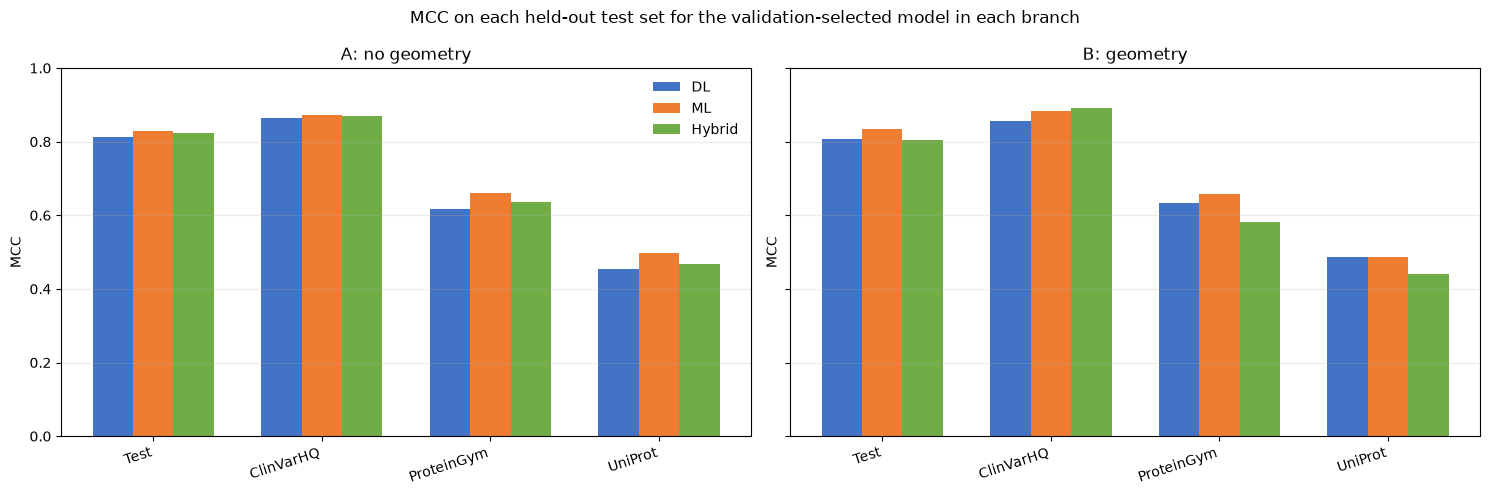

Comparison artifacts saved in: D:\Missense_variant_pathogenicity_prediction\experiments\optimization_fixed_config_20261018_064727\three_branch_comparison


In [ ]:
# Compare the validation-selected DL, ML and Hybrid models on each test set.
from pathlib import Path
import importlib
import core.module05v2_fusion_classifier.dl_ml_comparison as dl_ml_comparison_module
importlib.reload(dl_ml_comparison_module)

CURRENT_COMPARISON_INPUTS = [
    Path(pipeline.batch_run_dir) / "pure_dl_final_v1" / "all_dl_test_results.csv",
    Path(pipeline.batch_run_dir) / "xgb_no_pca" / "xgb_no_pca_test_metrics.csv",
    Path(pipeline.batch_run_dir) / "xgb_no_pca" / "xgb_no_pca_validation_metrics.csv",
    Path(pipeline.batch_run_dir) / "lightgbm" / "lightgbm_test_metrics.csv",
    Path(pipeline.batch_run_dir) / "lightgbm" / "lightgbm_validation_metrics.csv",
    Path(pipeline.batch_run_dir) / "catboost" / "catboost_test_metrics.csv",
    Path(pipeline.batch_run_dir) / "catboost" / "catboost_validation_metrics.csv",
    Path(pipeline.batch_run_dir) / "fixed_config_baseline.csv",
    Path(pipeline.batch_run_dir) / "hybrid_optuna_v2" / "hybrid_test_metrics.csv",
]
CURRENT_COMPARISON_MISSING = [str(path) for path in CURRENT_COMPARISON_INPUTS if not path.exists()]
if CURRENT_COMPARISON_MISSING:
    THREE_BRANCH_COMPARISON = None
    print("[SKIP] Current-batch three-branch comparison needs completed ML, Hybrid, and DL result files. Missing:\n" + "\n".join(CURRENT_COMPARISON_MISSING))
    print("Run the corresponding training/result cells first, including the Hybrid cell.")
else:
    THREE_BRANCH_COMPARISON = dl_ml_comparison_module.run_three_branch_comparison(pipeline, display_fn=display)


### Post-hoc SHAP / LIME (after training)

This cell loads saved checkpoints, selects configurations using validation metrics, and generates explanations for the test sets without retraining. By default it selects the top 10 unique XGBoost/Hybrid configurations by `Val_MCC` and explains all four test sets. After restarting the kernel, set `POSTHOC_BATCH_RUN_DIR` to the completed batch directory.


In [ ]:
# Ch? b?t cell n?y sau khi batch training ?? ho?n t?t.
RUN_POSTHOC_EXPLAINABILITY = False
POSTHOC_BATCH_RUN_DIR = None  # v? d?: '../experiments/batch_run_20261002_1200'
POSTHOC_TOP_N = 10  # unique configs; t?ng d?n n?u mu?n gi?i th?ch th?m
POSTHOC_SELECTION_METRIC = 'Val_MCC'
POSTHOC_DATASETS = None  # None = to?n b? 4 test set; ho?c danh s?ch t?n dataset
POSTHOC_EXPLAINABILITY = {
    'enable_shap': True,
    'enable_lime': True,
    'max_background_samples': 512,
    'max_explain_samples': 200,
    'max_lime_samples': 20,
    'lime_num_features': 20,
    'lime_num_samples': 2000,
    'shap_top_k': 30,
    'random_state': 42,
}

if RUN_POSTHOC_EXPLAINABILITY:
    if POSTHOC_BATCH_RUN_DIR is not None:
        pipeline.batch_run_dir = os.path.abspath(POSTHOC_BATCH_RUN_DIR)
        pipeline.metrics_csv_path = os.path.join(pipeline.batch_run_dir, 'global_leaderboard_metrics.csv')
    pipeline.explainability = POSTHOC_EXPLAINABILITY
    posthoc_result = pipeline.run_posthoc_explainability(
        metrics_path=pipeline.metrics_csv_path,
        top_n=POSTHOC_TOP_N,
        selection_metric=POSTHOC_SELECTION_METRIC,
        dataset_names=POSTHOC_DATASETS,
    )
    print(f"[*] Post-hoc outputs: {posthoc_result['summary_path']}")
    print(f"[*] Selected configs: {posthoc_result['num_selected_configs']}")
    print(f"[*] Dataset explanation runs: {posthoc_result['num_explained_dataset_runs']}")
    display(pd.DataFrame(posthoc_result['results']))
